# Sistema de Reconocimiento Facial para el Registro de Asistencias en un Gimnasio
## Prototipo Experimental — Metodología CRISP-DM

**Asignatura:** Machine Learning II  
**Arquitectura de IA:** FaceNet512 (modelo preentrenado) + MTCNN (detección y alineación)  
**Comparación:** distancia coseno entre embeddings faciales de 512 dimensiones  
**Estrategia de identificación:** vecino más cercano en una galería de matriculación (`todos_min`)  
**Integración prevista:** FastAPI, PostgreSQL con `pgvector` y Flutter

**Objetivo del notebook.** Desarrollar y evaluar el componente biométrico del sistema de control de asistencias, desde el análisis de fotografías hasta la exportación de embeddings y parámetros para su posterior integración. Se siguen las seis fases de CRISP-DM. **No se entrena ni se ajusta el peso del modelo FaceNet512**: se aprovechan los parámetros aprendidos previamente para generar representaciones faciales y se calibra únicamente la regla de decisión.

**Alcance del conjunto de datos.** Se cuenta con fotografías de 7 participantes (28 por persona; 196 fotografías en total). La planificación original contemplaba 13 personas, pero no se recibieron las imágenes de las otras 6. Las imágenes de desconocidos proceden de una colección externa (CelebA) y se utilizan exclusivamente para evaluar rechazos.

**Criterios de rigor.** Se mantienen separados los ejemplos de matriculación, validación y prueba; el umbral se selecciona usando exclusivamente validación. Se reportan las tasas de aceptación y rechazo, los denominadores de cada métrica y las limitaciones derivadas del tamaño de muestra y de las fotografías tomadas en sesiones similares.

**Protección de datos.** Fotografías y embeddings son datos biométricos: su tratamiento requiere autorización de los participantes, almacenamiento privado y acceso controlado. Las hojas de contacto incrustadas en este notebook **no deben compartirse públicamente**.


## Fase 1. Comprensión del negocio

El gimnasio necesita una alternativa al registro manual de ingresos, el sistema deberá reconocer a una persona previamente matriculada a partir de una captura facial, registrar fecha y hora de acceso y responder correctamente ante personas desconocidas o intentos repetidos.

**Objetivo general.** Desarrollar un prototipo de reconocimiento facial para apoyar el control automatizado de asistencias.

**Objetivos específicos.** (1) Obtener embeddings con FaceNet512 y MTCNN; (2) construir una galería de referencia; (3) calibrar una regla de reconocimiento con distancia coseno; (4) evaluar socios, desconocidos y tiempo de respuesta; (5) exportar artefactos para su uso en FastAPI y PostgreSQL.

**Criterios propuestos para el experimento:** exactitud de identificación de socios ≥ 95 %; FAR externa observada ≤ 1 %; FAR de identidades ocultas observada ≤ 1 %; error de identidad ≤ 1 %; latencia media local ≤ 3 s. Son **metas de diseño**, no garantías operativas; el cumplimiento se verifica posteriormente y por separado.

**Funciones del sistema final (fuera de este notebook):** alta de usuarios y toma de fotografías desde Flutter; extracción de embeddings mediante FastAPI; almacenamiento de usuarios, embeddings e intentos en PostgreSQL; clasificación de los intentos como `ACCEPTED`, `REJECTED` o `DUPLICATE`; consulta del historial de asistencias.


## Fase 2. Comprensión de los datos

**Origen y organización.** Las imágenes de matriculación están organizadas en `matriculacion/<persona>/<archivo>.jpg`. El nombre del archivo es libre (`foto_01.jpg`, `Foto_5.jpg`, etc.), siempre que tenga una extensión JPG, JPEG o PNG reconocida. Las fotografías de personas externas se encuentran en `desconocidos/`.

**Descripción del conjunto:** 196 fotografías de 7 identidades registradas, con variación de pose, expresión, uso de lentes e iluminación. Algunas se capturaron en una misma sesión y con fondos casi idénticos; por ello, una partición aleatoria puede producir resultados más optimistas que una evaluación con fotografías nuevas.

**Control de desconocidos.** Si CelebA se encuentra en una única carpeta, las imágenes se dividen por archivo, lo que **no garantiza** que la misma celebridad no aparezca en validación y prueba. La separación por identidad requiere subcarpetas identificadas o el archivo oficial `identity_CelebA.txt` (si está disponible).

**Exploración posterior:** inventario por persona, estado de extracción, confianza del detector, brillo, nitidez y revisión visual de todas las imágenes. Los estados generados por MTCNN son **resultados automáticos**, no verificaciones humanas definitivas.

**Entorno reproducible utilizado en la ejecución adjunta:** Python 3.11.17 y DeepFace 0.0.101. La configuración de TensorFlow y tf-keras debe conservarse para comparar resultados con la misma versión del modelo.


In [1]:
# Librerías necesarias para ejecutar el notebook
# %pip install "deepface==0.0.101" "tensorflow==2.17.0" "tf-keras==2.17.0" "opencv-python" "pandas" "matplotlib" "scikit-learn" "ipykernel"

from pathlib import Path
from datetime import datetime, timezone
import hashlib, json, math, platform, time

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import confusion_matrix, classification_report
from deepface import DeepFace
import deepface

SEMILLA = 42
RNG = np.random.default_rng(SEMILLA)
RAIZ = Path.cwd()
CARPETA_FOTOS = RAIZ / "matriculacion"
CARPETA_DESCONOCIDOS = RAIZ / "desconocidos"
CARPETA_SALIDA = RAIZ / "modelo_exportado"
EXT = {".jpg", ".jpeg", ".png"}

MODELO = "Facenet512"
DETECTOR = "mtcnn"
ALINEAR = True
NORMALIZACION_DEEPFACE = "base"  # coincide con el valor por defecto de la versión evaluada
MAX_LADO_IMAGEN = 1280
MIN_LADO_ROSTRO = 80
MIN_CONFIANZA = 0.90  # criterio del prototipo, puede descartar detecciones correctas
BRILLO_RECHAZO = (35, 235)
NITIDEZ_RECHAZO = 15.0  # criterio del prototipo, revisa sus falsos rechazos
DISTANCIA_DHASH_AVISO = 3   # solo AVISA sobre fotografías parecidas; NO las descarta
UMBRAL_DEFECTO = 0.30     # referencia inicial, NO el umbral final calibrado
FAR_MAX = 0.01

# Exclusiones por revisión VISUAL de fotografías que no pertenecen a la persona, con gorra, etc.
# Ejemplo: {"persona_01/foto_03.jpg", "persona_02/foto_12.jpg"}
EXCLUSIONES_MANUALES = set()
MOSTRAR_MOSAICOS = True   # se muestran y guardan las 28 fotos de cada persona, con su estado

print("Python:", platform.python_version(), "| DeepFace:", getattr(deepface, "__version__", "no informada"))
print("Carpeta de trabajo:", RAIZ)
print("Modelo:", MODELO, "| Detector:", DETECTOR, "| Umbral provisional:", UMBRAL_DEFECTO)

26-10-19 16:41:00 - ⚠️ 
 ⚠️ DEPRECATION WARNING:
 Running 'pip install deepface' alone will no longer be sufficient and will
 NOT install a default backend in an upcoming major release.

 Currently, TensorFlow is included by default, but this behavior will be deprecated.
 Please explicitly specify your preferred backend engine when installing:

   -> pip install deepface[tensorflow]
   -> pip install deepface[pytorch]

 Otherwise, you will encounter 'module not found' errors.


Python: 3.11.17 | DeepFace: 0.0.101
Carpeta de trabajo: C:\Users\Arman\Desktop\machine_learning_II\Proyecto Final
Modelo: Facenet512 | Detector: mtcnn | Umbral provisional: 0.3


In [2]:
assert CARPETA_FOTOS.is_dir(), f"Falta {CARPETA_FOTOS}. Crea matriculacion/<persona>/fotos."
rutas = sorted(p for p in CARPETA_FOTOS.iterdir() if p.is_dir())
filas = [(p.name, foto) for p in rutas for foto in sorted(p.iterdir()) if foto.is_file() and foto.suffix.lower() in EXT]
inventario = pd.DataFrame([{"persona": persona, "foto": ruta.name, "ruta": str(ruta)} for persona, ruta in filas])
assert not inventario.empty, "No se encontraron fotografías JPG/PNG en carpetas de personas."
resumen_inventario = inventario.groupby("persona").size().rename("fotos").to_frame()
resumen_inventario["esperadas"] = 28
resumen_inventario["diferencia"] = 28 - resumen_inventario["fotos"]
display(resumen_inventario)
print(f"Fotografías: {len(inventario)} | Personas: {len(resumen_inventario)} | Meta original: 13 × 28 = 364")
assert len(resumen_inventario) >= 2, "Se necesitan al menos 2 personas para simular desconocidos con exclusión de identidad."

,fotos,esperadas,diferencia
persona,,,
alexis_gonzalez,28,28,0
byron_melo,28,28,0
christian_villegas,28,28,0
dilan_salazar,28,28,0
genesis_escobar,28,28,0
ian_morales,28,28,0
mathew_lara,28,28,0


Fotografías: 196 | Personas: 7 | Meta original: 13 × 28 = 364


## Fase 3. Preparación de los datos

Se aplica una misma secuencia de procesamiento a todas las fotografías para que los vectores obtenidos sean comparables:

1. **Lectura con OpenCV (BGR).** Se carga la imagen y se limita su lado máximo a 1280 píxeles para controlar el costo de inferencia.
2. **Detección y alineación con MTCNN.** Se localiza el rostro y se ajusta su orientación; se exige una sola detección válida.
3. **Extracción de características con FaceNet512.** `DeepFace.represent` produce un embedding de 512 números usando el modelo preentrenado, sin modificar sus pesos.
4. **Control de calidad.** Se revisan confianza de detección, tamaño del recorte, brillo y nitidez. Son heurísticas configurables, no medidas infalibles de identidad o usabilidad.
5. **Normalización L2.** Cada embedding se divide por su norma para obtener un vector unitario, lo cual facilita el cálculo consistente de distancia coseno.
6. **Control de duplicados.** SHA-256 detecta archivos exactamente iguales; dHash **solo advierte** de imágenes visualmente parecidas, que pueden contener poses útiles y por tanto no se excluyen automáticamente.

Cuando MTCNN informa `SIN_ROSTRO` o `VARIOS_ROSTROS`, el resultado se marca para revisión. Un segundo rostro detectado **puede ser un falso positivo del detector**. Las hojas de contacto permiten inspeccionar esas incidencias visualmente, pero no autorizan por sí solas el ingreso de imágenes ambiguas a la galería.

**Productos de la fase:** tabla de calidad, embeddings válidos y hojas de contacto con las fotografías originales.


In [3]:
def leer_bgr(origen):
    '''Lee una fotografía y limita su tamaño; conserva el espacio de color BGR para DeepFace.'''
    img = cv2.imread(str(origen)) if isinstance(origen, (str, Path)) else origen
    if img is None or not hasattr(img, "shape") or img.ndim != 3 or img.shape[2] != 3:
        return None
    alto, ancho = img.shape[:2]
    escala = min(1.0, MAX_LADO_IMAGEN / max(alto, ancho))
    if escala < 1:
        img = cv2.resize(img, (max(1, round(ancho * escala)), max(1, round(alto * escala))), interpolation=cv2.INTER_AREA)
    return img

def vector_unitario(v):
    v = np.asarray(v, dtype=np.float32)
    norma = float(np.linalg.norm(v))
    if v.shape != (512,) or not np.isfinite(v).all() or norma < 1e-10:
        raise ValueError("Embedding inválido: se requieren 512 números finitos.")
    return v / norma

def hash_perceptual(img):
    '''Huella perceptual de 64 bits sobre la imagen completa; es una advertencia, no una prueba de duplicidad.'''
    gris = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    pequeño = cv2.resize(gris, (9, 8), interpolation=cv2.INTER_AREA)
    bits = pequeño[:, 1:] > pequeño[:, :-1]
    return int("".join("1" if x else "0" for x in bits.ravel()), 2)

def extraer_embedding(origen):
    '''Extrae un embedding válido con el mismo procesamiento que deberá reproducirse en FastAPI.'''
    img = leer_bgr(origen)
    if img is None:
        return {"estado": "ARCHIVO_ILEGIBLE", "motivo": "No se pudo leer una imagen BGR"}
    try:
        rostros = DeepFace.represent(
            img_path=img, model_name=MODELO, detector_backend=DETECTOR,
            enforce_detection=True, align=ALINEAR,
            normalization=NORMALIZACION_DEEPFACE,
        )
    except ValueError as exc:
        mensaje = str(exc).lower()
        if "could not be detected" in mensaje or "no face detected" in mensaje or "face is not detected" in mensaje:
            return {"estado": "SIN_ROSTRO", "motivo": str(exc)[:150]}
        raise  # errores de instalación/modelo se muestran; no deben disfrazarse como "sin rostro"
    if len(rostros) == 0:
        return {"estado": "SIN_ROSTRO", "motivo": "Detector sin resultados"}
    if len(rostros) != 1:
        return {"estado": "VARIOS_ROSTROS", "motivo": f"Rostros detectados: {len(rostros)}"}
    rostro = rostros[0]
    area = rostro["facial_area"]
    x, y, w, h = (int(area[k]) for k in ("x", "y", "w", "h"))
    hh, ww = img.shape[:2]
    x1, y1, x2, y2 = max(0, x), max(0, y), min(ww, x + w), min(hh, y + h)
    if x2 <= x1 or y2 <= y1:
        return {"estado": "ROSTRO_BAJA_CALIDAD", "motivo": "Recorte facial vacío"}
    crop = img[y1:y2, x1:x2]
    gris = cv2.cvtColor(crop, cv2.COLOR_BGR2GRAY)
    gris160 = cv2.resize(gris, (160, 160))
    brillo = float(gris.mean())
    nitidez = float(cv2.Laplacian(gris160, cv2.CV_64F).var())
    confianza = float(rostro.get("face_confidence") or 0.0)
    lado = min(x2 - x1, y2 - y1)
    medidas = {"confianza": confianza, "lado_rostro": int(lado), "brillo": brillo, "nitidez": nitidez}
    if confianza < MIN_CONFIANZA or lado < MIN_LADO_ROSTRO or not (BRILLO_RECHAZO[0] <= brillo <= BRILLO_RECHAZO[1]) or nitidez < NITIDEZ_RECHAZO:
        return {"estado": "ROSTRO_BAJA_CALIDAD", "motivo": "No cumple umbrales mínimos de confianza/tamaño/luz/nitidez", **medidas}
    emb = vector_unitario(rostro["embedding"])
    return {"estado": "OK", "motivo": "", "embedding": emb, "dhash": hash_perceptual(img), **medidas}

In [4]:
# Extraer 512 valores de cada foto. Las 196 imágenes se procesan con MTCNN y FaceNet512.
# Solo se elimina automáticamente una copia EXACTA de archivos; la similitud dHash se AVISA.
# ¡La misma foto etiquetada como dos personas diferentes constituye un error de etiquetas!
firmas_entre_personas = {}
firmas_dentro_persona = {}
registros, vectores = [], {}
inicio = time.perf_counter()
for i, r in enumerate(inventario.itertuples(index=False), start=1):
    clave = f"{r.persona}/{r.foto}"
    firma = hashlib.sha256(Path(r.ruta).read_bytes()).hexdigest()
    if firma in firmas_entre_personas and firmas_entre_personas[firma][0] != r.persona:
        raise ValueError(f"La misma foto figura con dos identidades: {firmas_entre_personas[firma][1]} y {r.ruta}")
    firmas_entre_personas[firma] = (r.persona, r.ruta)
    codigo = (r.persona, firma)
    if codigo in firmas_dentro_persona:
        resultado = {"estado": "DUPLICADA_EXACTA", "motivo": f"Mismos bytes que {firmas_dentro_persona[codigo]}"}
    else:
        firmas_dentro_persona[codigo] = r.foto
        resultado = extraer_embedding(r.ruta)
    estado, motivo = resultado["estado"], resultado.get("motivo", "")
    if clave in EXCLUSIONES_MANUALES:
        estado, motivo = "EXCLUIDA_MANUAL", "Exclusión del equipo después de inspección"
    fila = {"persona": r.persona, "foto": r.foto, "ruta": r.ruta, "estado": estado,
            "motivo": motivo, "aviso_similitud": "",
            **{k: resultado.get(k, np.nan) for k in ("confianza", "lado_rostro", "brillo", "nitidez")}}
    if estado == "OK":
        fila["dhash"] = resultado["dhash"]
        vectores[r.ruta] = resultado["embedding"]
    registros.append(fila)
    if i % 25 == 0 or i == len(inventario):
        print(f"Analizadas {i}/{len(inventario)} fotografías")
calidad = pd.DataFrame(registros)

# dHash es una alarma para que una persona REVISE las imágenes, NO un filtro de embeddings.
for persona, grupo in calidad[calidad["estado"] == "OK"].groupby("persona", sort=True):
    vistos = []
    for indice in grupo.index:
        dh = int(calidad.at[indice, "dhash"])
        parecido = next((j for j, h in vistos if (dh ^ h).bit_count() <= DISTANCIA_DHASH_AVISO), None)
        if parecido is not None:
            calidad.at[indice, "aviso_similitud"] = f"Parecida visualmente a {calidad.at[parecido, 'foto']} (no eliminada)"
        vistos.append((indice, dh))

calidad_publica = calidad.drop(columns=["dhash"], errors="ignore")
CARPETA_SALIDA.mkdir(parents=True, exist_ok=True)
calidad_publica.to_csv(CARPETA_SALIDA / "calidad_fotos.csv", index=False)
display(calidad.pivot_table(index="persona", columns="estado", values="foto", aggfunc="count", fill_value=0))
print(f"Embeddings utilizables: {len(vectores)} de {len(inventario)} | Tiempo: {time.perf_counter()-inicio:.1f} s")
print("Avisos de parecido visual SIN eliminación:", int(calidad["aviso_similitud"].ne("").sum()))
print("Incidencias a revisar (son decisiones del detector, no hechos verificados):")
display(calidad_publica.loc[calidad_publica["estado"] != "OK", ["persona", "foto", "estado", "motivo"]].to_string(index=False))

Analizadas 25/196 fotografías
Analizadas 50/196 fotografías
Analizadas 75/196 fotografías
Analizadas 100/196 fotografías
Analizadas 125/196 fotografías
Analizadas 150/196 fotografías
Analizadas 175/196 fotografías
Analizadas 196/196 fotografías


estado,OK,VARIOS_ROSTROS
persona,,
alexis_gonzalez,28,0
byron_melo,28,0
christian_villegas,27,1
dilan_salazar,28,0
genesis_escobar,28,0
ian_morales,24,4
mathew_lara,28,0


Embeddings utilizables: 191 de 196 | Tiempo: 164.8 s
Avisos de parecido visual SIN eliminación: 42
Incidencias a revisar (son decisiones del detector, no hechos verificados):


'           persona        foto         estado                motivo\nchristian_villegas foto_04.jpg VARIOS_ROSTROS Rostros detectados: 2\n       ian_morales foto_20.jpg VARIOS_ROSTROS Rostros detectados: 2\n       ian_morales foto_21.jpg VARIOS_ROSTROS Rostros detectados: 2\n       ian_morales foto_22.jpg VARIOS_ROSTROS Rostros detectados: 2\n       ian_morales foto_27.jpg VARIOS_ROSTROS Rostros detectados: 2'

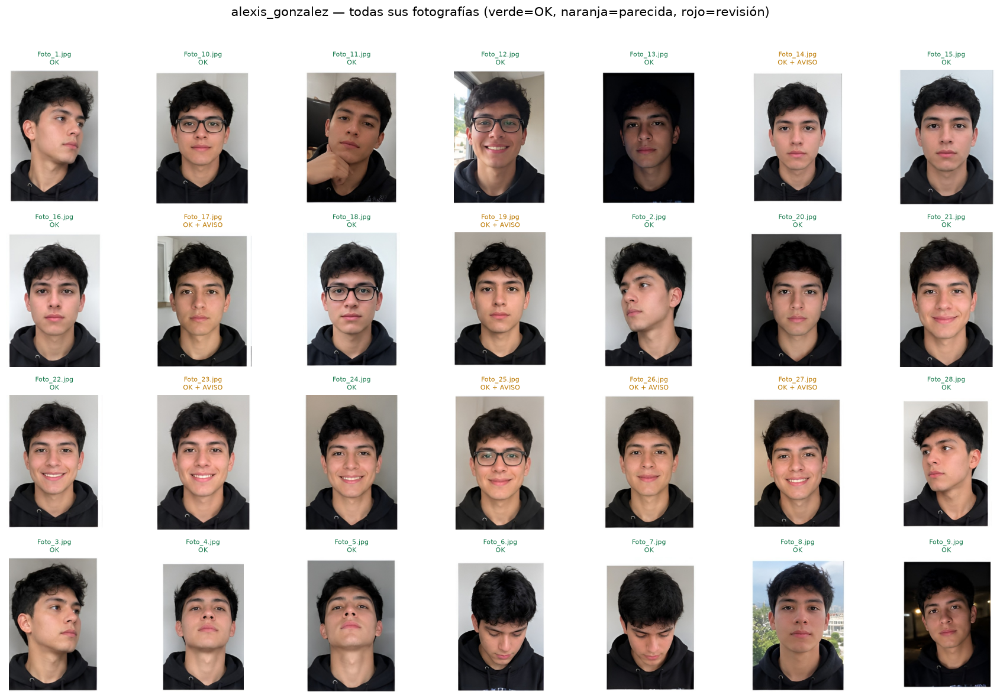

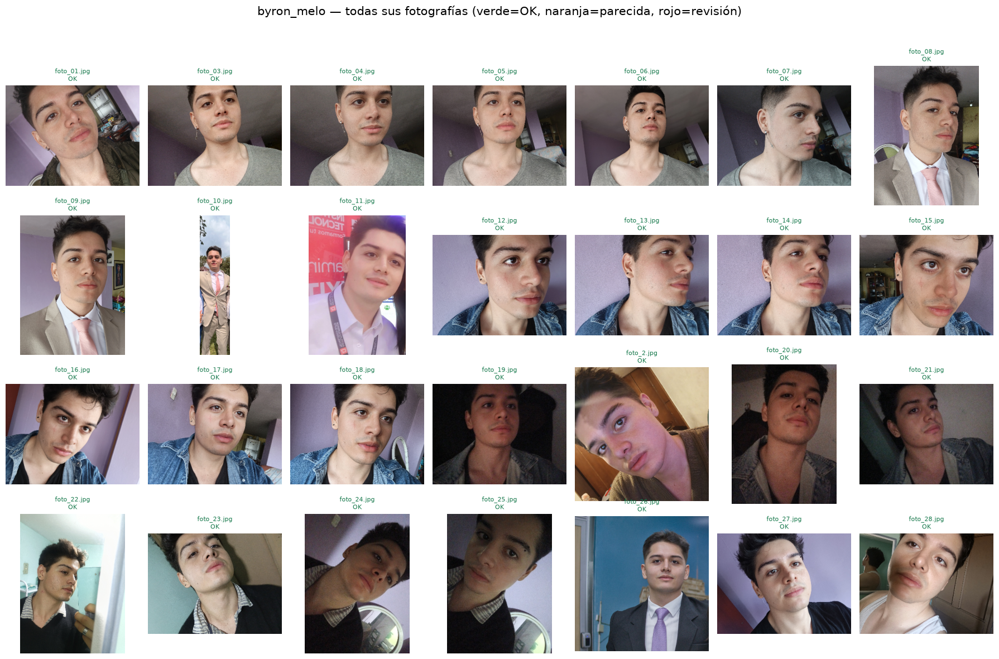

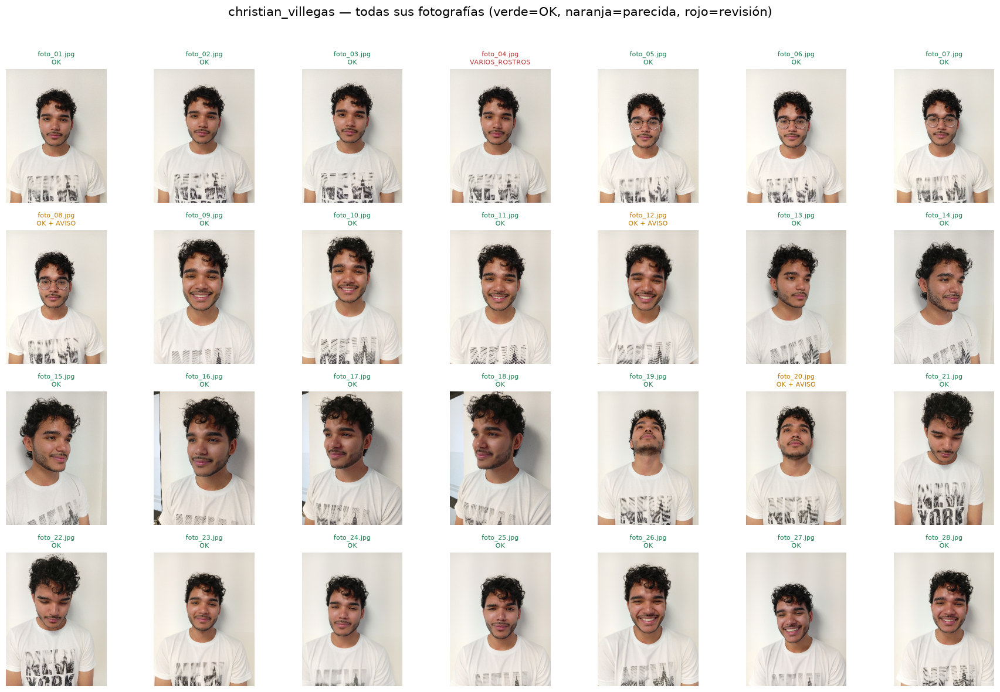

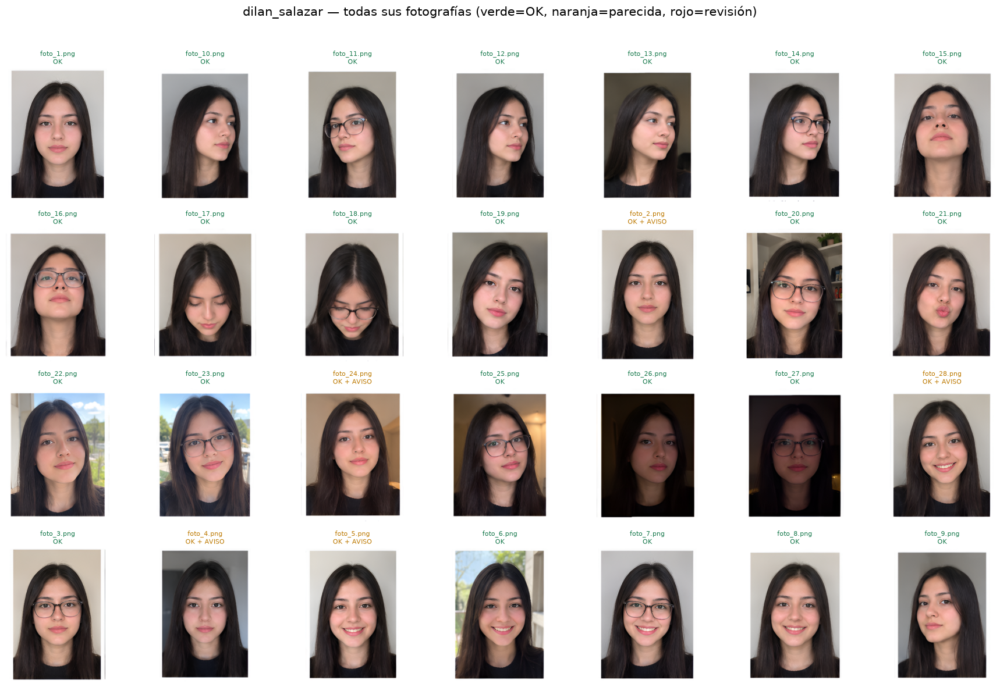

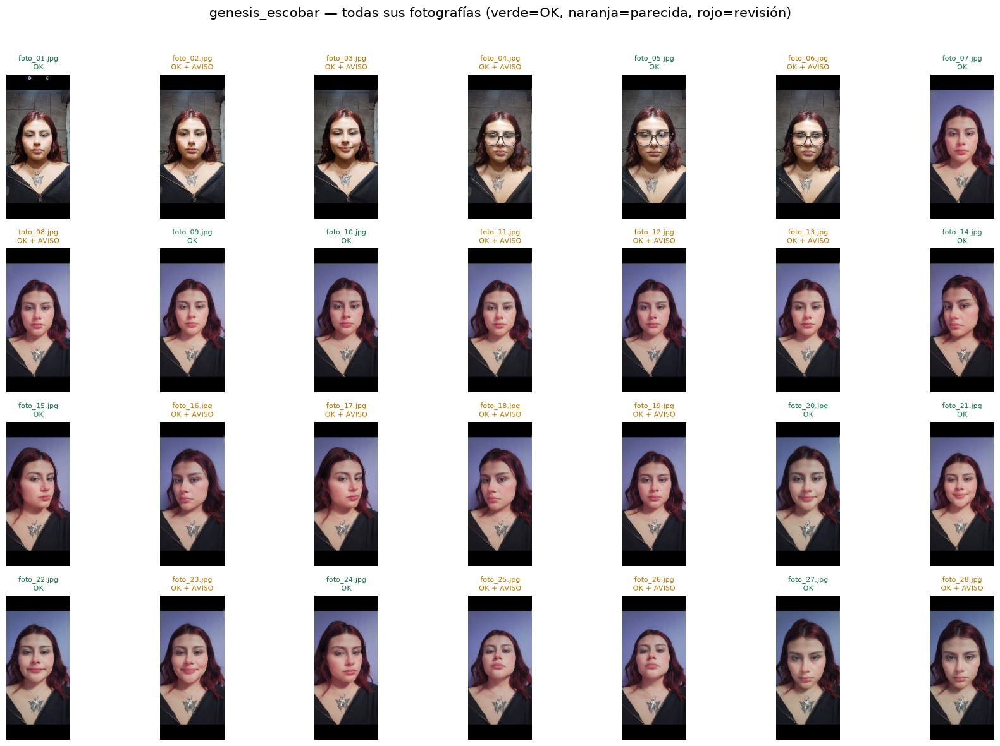

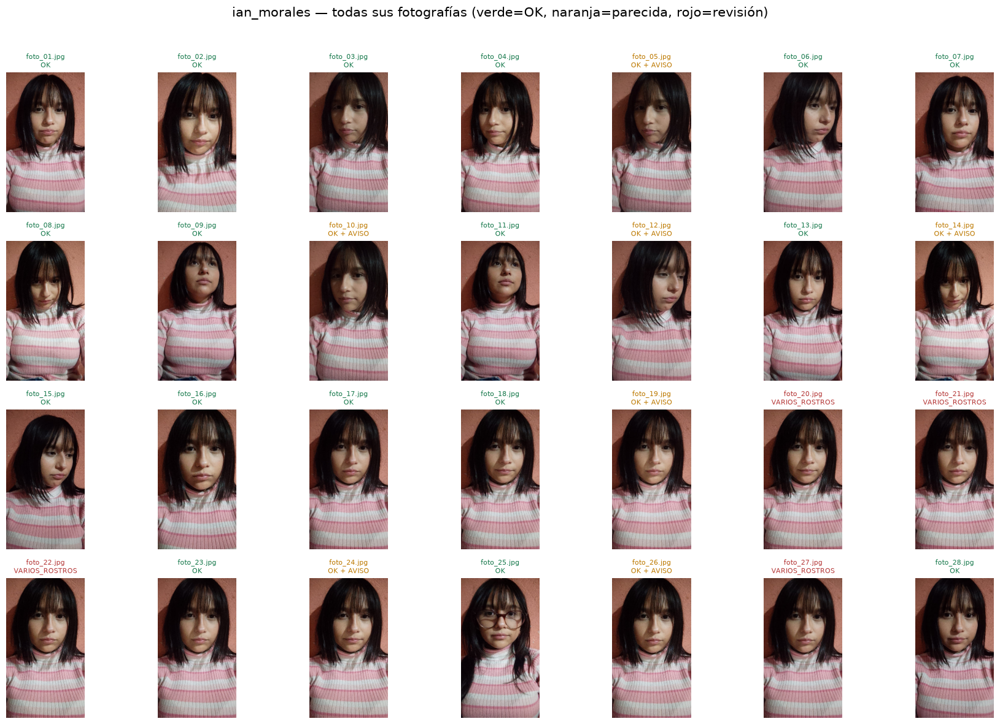

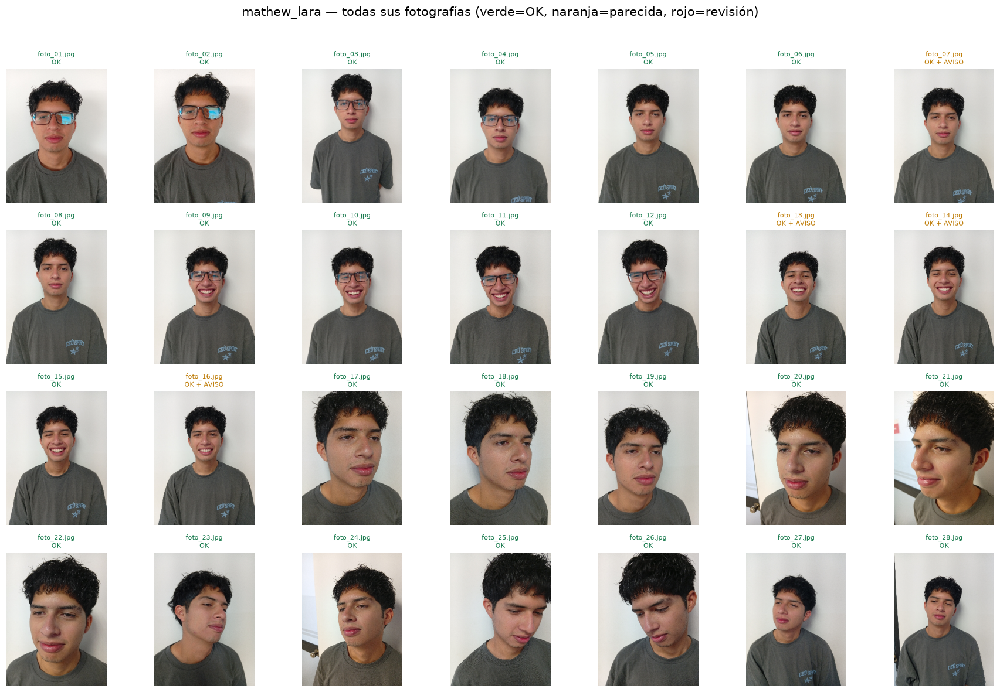

Mostradas 196 fotos y guardadas 7 hojas de contacto en C:\Users\Arman\Desktop\machine_learning_II\Proyecto Final\modelo_exportado\mosaicos


In [5]:
# HOJAS DE CONTACTO. Se muestran TODAS las fotos originales por persona: 7 × 28 = 196.
# Se guardan también en modelo_exportado/mosaicos para la exposición. NO las publiques en internet.
if MOSTRAR_MOSAICOS:
    carpeta_mosaicos = CARPETA_SALIDA / "mosaicos"
    carpeta_mosaicos.mkdir(exist_ok=True, parents=True)
    for persona, grupo in calidad.groupby("persona", sort=True):
        ncolumnas = 7
        nfilas = math.ceil(len(grupo) / ncolumnas)
        fig, ejes = plt.subplots(nfilas, ncolumnas, figsize=(18, nfilas * 3.0))
        for ax in np.asarray(ejes).reshape(-1):
            ax.axis("off")
        for ax, r in zip(np.asarray(ejes).reshape(-1), grupo.itertuples(index=False)):
            imagen = cv2.imread(str(r.ruta))
            if imagen is not None:
                hh, ww = imagen.shape[:2]
                esc = min(1.0, 320/max(hh, ww))
                if esc < 1:
                    imagen = cv2.resize(imagen, (max(1, round(ww * esc)), max(1, round(hh * esc))))
                ax.imshow(cv2.cvtColor(imagen, cv2.COLOR_BGR2RGB))
            etiqueta = r.estado + (" + AVISO" if r.aviso_similitud else "")
            color = "#B53737" if r.estado != "OK" else ("#BD7900" if r.aviso_similitud else "#17794C")
            ax.set_title(f"{r.foto}\n{etiqueta}", fontsize=8, color=color)
        fig.suptitle(f"{persona} — todas sus fotografías (verde=OK, naranja=parecida, rojo=revisión)", fontsize=15)
        fig.tight_layout(rect=(0, 0, 1, 0.96))
        destino = carpeta_mosaicos / f"{persona}.png"
        fig.savefig(destino, dpi=115, bbox_inches="tight")
        plt.show()
        plt.close(fig)
    print(f"Mostradas {len(calidad)} fotos y guardadas {len(calidad['persona'].unique())} hojas de contacto en {carpeta_mosaicos}")
else:
    print("Hojas de contacto ocultas. Cambia MOSTRAR_MOSAICOS=True en la configuración para mostrarlas.")

### División de las imágenes en matriculación, validación y prueba

Las fotografías con estado `OK` se reparten **por persona** en tres subconjuntos disjuntos. Con 28 imágenes utilizables por identidad, la proporción aproximada es **16 para matricular, 4 para validar y 8 para prueba**. Cuando se dispone de menos imágenes, se ajusta la cantidad manteniendo ejemplos en los tres conjuntos.

- **Matriculación:** embeddings de referencia almacenados en la galería (equivale al *enrollment* biométrico).
- **Validación:** capturas no incluidas en la galería para **calibrar** el umbral de aceptación.
- **Prueba:** capturas reservadas que sirven para **estimar el desempeño** después de fijar el umbral.

Se utiliza una semilla pseudoaleatoria fija (`SEMILLA=42`) para repetir el reparto. Esta separación **evita reutilizar el mismo archivo**, pero no asegura independencia de sesiones: fotografías casi idénticas tomadas en el mismo momento pueden aparecer en conjuntos distintos. Una evaluación posterior con capturas nuevas será necesaria para medir condiciones reales de uso.


In [6]:
base = calidad[calidad["estado"] == "OK"].copy().reset_index(drop=True)
conteos = base.groupby("persona").size()
if len(conteos) < 2 or (conteos < 8).any():
    raise ValueError(f"Se requieren >= 8 fotos usables por persona y >= 2 personas. Conteos:\n{conteos.to_string()}")

rng_split = np.random.default_rng(SEMILLA)  # no cambia al reejecutar esta celda
partes = []
for persona, g in base.groupby("persona", sort=True):
    indices = rng_split.permutation(g.index.to_numpy())
    n = len(indices)
    n_test = max(2, round(n * 8 / 28))
    n_val = max(2, round(n * 4 / 28))
    if n - n_test - n_val < 3:
        raise ValueError(f"No quedan fotos para matricular a {persona}")
    destinos = {int(k): "prueba" for k in indices[:n_test]}
    destinos.update({int(k): "validacion" for k in indices[n_test:n_test + n_val]})
    destinos.update({int(k): "matricular" for k in indices[n_test + n_val:]})
    partes.extend((int(i), tipo) for i, tipo in destinos.items())
base["conjunto"] = base.index.map(dict(partes))
assert not base["conjunto"].isna().any()
base[["persona", "foto", "conjunto", "estado"]].to_csv(CARPETA_SALIDA / "particion.csv", index=False)
display(base.pivot_table(index="persona", columns="conjunto", values="foto", aggfunc="count", fill_value=0))
print("Partición guardada. No modificar semillas ni fotos después de observar los resultados de prueba.")

conjunto,matricular,prueba,validacion
persona,,,
alexis_gonzalez,16,8,4
byron_melo,16,8,4
christian_villegas,15,8,4
dilan_salazar,16,8,4
genesis_escobar,16,8,4
ian_morales,14,7,3
mathew_lara,16,8,4


Partición guardada. No modificar semillas ni fotos después de observar los resultados de prueba.



## Fase 4. Modelado: identificación a partir de embeddings

En este proyecto, «modelado» **no equivale a reentrenar** FaceNet512. El modelo ya fue entrenado previamente; aquí se construye una regla de identificación a partir de los embeddings de referencia.

**Estrategia elegida — `todos_min`.** Se calcula la distancia coseno entre el embedding de consulta y **cada embedding** de la galería, se conserva la menor distancia y se obtiene la identidad asociada a ese vector.

Para dos embeddings normalizados mediante L2 (vectores de norma 1), la distancia coseno se calcula como:

$$
d_{\mathrm{cos}}(\mathbf{x}, \mathbf{y}) = 1 - \mathbf{x} \cdot \mathbf{y}
$$

Donde:

- $\mathbf{x}$: embedding del rostro que se desea reconocer.
- $\mathbf{y}$: embedding de referencia almacenado en la galería.
- $\mathbf{x} \cdot \mathbf{y}$: producto punto entre ambos vectores.
- $d_{\mathrm{cos}}$: distancia coseno entre los embeddings.

**Interpretación:** una distancia menor indica mayor similitud facial. Una distancia cercana a cero representa embeddings muy similares.

La identidad del vecino más cercano **todavía no implica aceptación**. En la siguiente fase se selecciona un umbral máximo mediante validación. Si la menor distancia supera dicho umbral, el sistema responde `DESCONOCIDO`.

La comparación es compatible con el operador de distancia coseno `<=>` de `pgvector`, previsto para la futura base de datos PostgreSQL.


In [7]:
def formar_galeria(tabla):
    assert len(tabla) > 0, "La galería no puede estar vacía"
    G = np.stack([vectores[r] for r in tabla["ruta"]]).astype(np.float32)
    nombres = tabla["persona"].to_numpy()
    return G, nombres

def puntuar(tabla, galeria):
    '''Consulta la galería y devuelve vecino más cercano y distancia sin decisión de aceptación.'''
    G, nombres = galeria
    if len(tabla) == 0:
        return pd.DataFrame(columns=["persona", "foto", "mejor", "distancia"])
    X = np.stack([vectores[r] for r in tabla["ruta"]]).astype(np.float32)
    distancias = np.clip(1.0 - X @ G.T, 0.0, 2.0)
    idx = np.argmin(distancias, axis=1)
    return pd.DataFrame({"persona": tabla["persona"].to_numpy(), "foto": tabla["foto"].to_numpy(),
                         "mejor": nombres[idx], "distancia": distancias[np.arange(len(idx)), idx]})

def evaluar_ocultos(tabla, galeria):
    '''Retira cada identidad de la galería y mide si sería aceptada como otra; escenario simulado.'''
    G, nombres = galeria
    salida = []
    for persona, fotos in tabla.groupby("persona"):
        mascara = nombres != persona
        if not mascara.any():
            continue
        pred = puntuar(fotos, (G[mascara], nombres[mascara]))
        salida.append(pred.assign(tipo="identidad_oculta"))
    return pd.concat(salida, ignore_index=True) if salida else pd.DataFrame(columns=["distancia"])

matricular = base[base["conjunto"] == "matricular"]
validacion = base[base["conjunto"] == "validacion"]
prueba = base[base["conjunto"] == "prueba"]
galeria = formar_galeria(matricular)
val_socios = puntuar(validacion, galeria)
val_ocultos = evaluar_ocultos(validacion, galeria)
print(f"Galería: {len(matricular)} embeddings / {len(set(galeria[1]))} personas")
print(f"Validación: {len(val_socios)} intentos de socios y {len(val_ocultos)} intentos con identidad oculta")

Galería: 109 embeddings / 7 personas
Validación: 27 intentos de socios y 27 intentos con identidad oculta


## Fase 5. Evaluación del sistema de reconocimiento

Se evalúan tres situaciones **por separado**: (a) consultas de socios existentes contra la galería completa; (b) simulación de identidades ocultas, retirando una identidad de la galería antes de consultarla; y (c) imágenes de personas externas tomadas de CelebA.

| Indicador | Significado operacional |
|---|---|
| **Exactitud de socios** | Consultas válidas de socios respondidas con su identidad correcta / total de consultas válidas de socios |
| **FRR** — *False Rejection Rate* | Socios válidos rechazados como `DESCONOCIDO` / consultas válidas de socios |
| **Error de identidad** | Socios aceptados con el nombre de otro socio / consultas válidas de socios |
| **FAR ocultos** — *False Acceptance Rate* | Consultas de identidades temporalmente retiradas aceptadas como alguna identidad que permanece en la galería / total de consultas ocultas |
| **FAR externa** | Rostros externos aceptados como algún socio / total de rostros externos válidos ensayados |

La **calibración** usa solamente el conjunto de validación y los desconocidos asignados a calibración. Después se mantiene fijo el umbral durante la **prueba final**. La exactitud reportada es **condicional a imágenes con extracción satisfactoria**; la cobertura de imágenes utilizables se informa por separado.

**Limitaciones estadísticas:** FAR oculta y FAR externa son experimentos diferentes. Cero aceptaciones indebidas observadas no prueba FAR real nula. La división de CelebA por archivo y la similitud entre imágenes capturadas en una misma sesión limitan la independencia de los ensayos.


In [8]:
# Desconocidos externos; separarlos por identidad si existe subcarpeta o etiqueta oficial CelebA.
# CelebA identity_CelebA.txt: cada línea debe tener "000001.jpg 123", por ejemplo.
rutas_externas = sorted(p for p in CARPETA_DESCONOCIDOS.rglob("*")
                       if p.is_file() and p.suffix.lower() in EXT) if CARPETA_DESCONOCIDOS.is_dir() else []

archivo_ids = RAIZ / "identity_CelebA.txt"
identidades_celeba = {}
if archivo_ids.is_file():
    for linea in archivo_ids.read_text(encoding="utf-8", errors="replace").splitlines():
        trozos = linea.split()
        if len(trozos) == 2:
            identidades_celeba[trozos[0]] = f"celeba_sujeto_{trozos[1]}"
    print(f"Etiquetas de identidad CelebA cargadas: {len(identidades_celeba)} imágenes")

filas_ext, vectores_ext = [], {}
for i, ruta in enumerate(rutas_externas, 1):
    resultado = extraer_embedding(ruta)
    if ruta.parent != CARPETA_DESCONOCIDOS:
        identidad = f"carpeta::{ruta.parent.name}"
    else:
        identidad = identidades_celeba.get(ruta.name, f"archivo::{ruta.name}")
    if resultado["estado"] == "OK":
        vectores_ext[str(ruta)] = resultado["embedding"]
    filas_ext.append({"ruta": str(ruta), "identidad": identidad, "estado": resultado["estado"]})
    if i % 50 == 0 or i == len(rutas_externas):
        print(f"Desconocidos procesados: {i}/{len(rutas_externas)}")
ext = pd.DataFrame(filas_ext, columns=["ruta", "identidad", "estado"])
ext_ok = ext[ext["estado"] == "OK"].copy()
if not ext_ok.empty:
    rng_ext = np.random.default_rng(SEMILLA + 1)
    ids = rng_ext.permutation(ext_ok["identidad"].unique())
    n_cal = max(1, len(ids) // 2)
    ids_cal = set(ids[:n_cal])
    ext_ok["conjunto"] = np.where(ext_ok["identidad"].isin(ids_cal), "calibracion", "prueba")
else:
    ext_ok["conjunto"] = pd.Series(dtype="str")

def distancias_externas(tabla, galeria):
    if tabla.empty:
        return np.array([], dtype=np.float32)
    G, _ = galeria
    X = np.stack([vectores_ext[r] for r in tabla["ruta"]]).astype(np.float32)
    return np.clip(1.0 - X @ G.T, 0.0, 2.0).min(axis=1)

ext_cal = ext_ok[ext_ok["conjunto"] == "calibracion"]
ext_test = ext_ok[ext_ok["conjunto"] == "prueba"]
d_cal_ext = distancias_externas(ext_cal, galeria)
print(f"Desconocidos externos: {len(ext)} imágenes, {len(ext_ok)} rostros válidos")
print(f"Calibración externa: {len(d_cal_ext)} | Prueba externa RESERVADA: {len(ext_test)}")
if len(ext) and any(e.startswith("archivo::") for e in ext_ok["identidad"]):
    print("[LIMITACIÓN] Hay fotos CelebA sin identidad: la división por archivo puede mezclar famosos.")
if len(d_cal_ext) == 0:
    print("[LIMITACIÓN] Sin desconocidos externos para calibrar: se usa identidad oculta.")

Desconocidos procesados: 50/201
Desconocidos procesados: 100/201
Desconocidos procesados: 150/201
Desconocidos procesados: 200/201
Desconocidos procesados: 201/201
Desconocidos externos: 201 imágenes, 160 rostros válidos
Calibración externa: 80 | Prueba externa RESERVADA: 80
[LIMITACIÓN] Hay fotos CelebA sin identidad: la división por archivo puede mezclar famosos.


Umbral calibrado con VALIDACIÓN: 0.260
Exactitud en validación: 92.6% | FAR identidades ocultas: 0.0%
FAR externos en validación: 0.0%


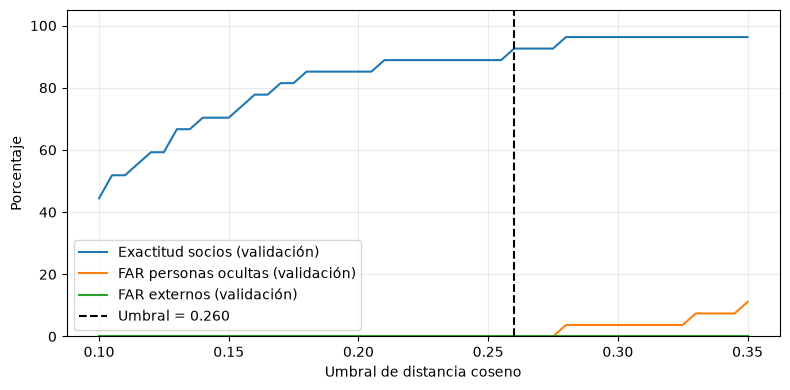

In [9]:
# Elegimos umbral mirando SOLO las fotografías de VALIDACIÓN.
# FAR de identidades ocultas y FAR de externos se mantienen SEPARADAS.
d_val_ocultos = val_ocultos["distancia"].to_numpy(dtype=float)
aciertos_val = (val_socios["mejor"].to_numpy() == val_socios["persona"].to_numpy())
d_val_socios = val_socios["distancia"].to_numpy(dtype=float)

filas_umbral = []
for t in np.round(np.arange(0.10, 0.351, 0.005), 3):
    exactitud = float(np.mean(aciertos_val & (d_val_socios <= t)))
    far_ocultos = float(np.mean(d_val_ocultos <= t))
    far_externos = float(np.mean(d_cal_ext <= t)) if len(d_cal_ext) else np.nan
    cumple = far_ocultos <= FAR_MAX and (not len(d_cal_ext) or far_externos <= FAR_MAX)
    filas_umbral.append({"umbral": float(t), "exactitud_val": exactitud,
                          "FAR_ocultos_val": far_ocultos, "FAR_externos_val": far_externos, "cumple_FAR": cumple})
tabla_umbral = pd.DataFrame(filas_umbral)
validos = tabla_umbral[tabla_umbral["cumple_FAR"]]
if validos.empty:
    # Política conservadora documentada: de no existir ningún umbral bajo FAR objetivo,
    # elegimos el mínimo observado; NO declarar los criterios como cumplidos.
    UMBRAL_FINAL = float(tabla_umbral.iloc[0]["umbral"])
    print("[ADVERTENCIA] Ningún umbral cumple FAR objetivo; se eligió el más restrictivo. Revisar datos.")
else:
    mejor_exactitud = validos["exactitud_val"].max()
    # Si varios umbrales logran la misma exactitud, escoger el MENOR por seguridad.
    UMBRAL_FINAL = float(validos[validos["exactitud_val"] >= mejor_exactitud - 1e-12]["umbral"].min())

fila_cal = tabla_umbral.loc[np.isclose(tabla_umbral["umbral"], UMBRAL_FINAL)].iloc[0]
print(f"Umbral calibrado con VALIDACIÓN: {UMBRAL_FINAL:.3f}")
print(f"Exactitud en validación: {fila_cal['exactitud_val']:.1%} | FAR identidades ocultas: {fila_cal['FAR_ocultos_val']:.1%}")
if len(d_cal_ext):
    print(f"FAR externos en validación: {fila_cal['FAR_externos_val']:.1%}")
plt.figure(figsize=(8, 4))
plt.plot(tabla_umbral["umbral"], tabla_umbral["exactitud_val"] * 100, label="Exactitud socios (validación)")
plt.plot(tabla_umbral["umbral"], tabla_umbral["FAR_ocultos_val"] * 100, label="FAR personas ocultas (validación)")
if len(d_cal_ext):
    plt.plot(tabla_umbral["umbral"], tabla_umbral["FAR_externos_val"] * 100, label="FAR externos (validación)")
plt.axvline(UMBRAL_FINAL, ls="--", color="black", label=f"Umbral = {UMBRAL_FINAL:.3f}")
plt.xlabel("Umbral de distancia coseno")
plt.ylabel("Porcentaje")
plt.ylim(0, 105)
plt.legend(); plt.grid(alpha=0.25); plt.tight_layout(); plt.show()

### Prueba final con el umbral fijado

La siguiente celda evalúa **una sola vez** los subconjuntos reservados de socios, identidades ocultas y desconocidos externos, utilizando el umbral calibrado. **No se ajusta el umbral observando la prueba**, aunque algún valor alternativo reconozca más fotografías.

Se informan proporciones, denominadores e **intervalos de Wilson al 95 %**. Estos intervalos ilustran la incertidumbre bajo una aproximación de observaciones independientes; en fotografías correlacionadas de una misma sesión pueden subestimar la incertidumbre real. Por ello, la validación en capturas independientes sigue siendo importante.


In [10]:
def proporcion_intervalo(exitos, n):
    '''Intervalo de Wilson al 95 % para una proporción binomial (aproximado).'''
    if n <= 0:
        return None
    z = 1.96
    p = exitos / n
    den = 1 + z*z/n
    centro = (p + z*z/(2*n)) / den
    mitad = z * math.sqrt((p*(1-p) + z*z/(4*n)) / n) / den
    return [max(0.0, centro - mitad), min(1.0, centro + mitad)]

prueba_socios = puntuar(prueba, galeria)
prueba_ocultos = evaluar_ocultos(prueba, galeria)
d_test_ext = distancias_externas(ext_test, galeria)

acepta_socios = prueba_socios["distancia"].to_numpy() <= UMBRAL_FINAL
correctos_socios = acepta_socios & (prueba_socios["mejor"].to_numpy() == prueba_socios["persona"].to_numpy())
errores_identidad = acepta_socios & ~correctos_socios
rechazos_socios = ~acepta_socios

N = len(prueba_socios)
N_correctos = int(correctos_socios.sum())
N_error = int(errores_identidad.sum())
N_rechazo = int(rechazos_socios.sum())
far_ocultos_test = int((prueba_ocultos["distancia"].to_numpy() <= UMBRAL_FINAL).sum())
far_ext_test = int((d_test_ext <= UMBRAL_FINAL).sum())

metricas_finales = {
    "personas": int(base["persona"].nunique()),
    "fotos_originales": int(len(inventario)),
    "fotos_usables": int(len(base)),
    "proporcion_fotos_usables": float(len(base) / len(inventario)),
    "embeddings_matriculacion": int(len(matricular)),
    "umbral": UMBRAL_FINAL,
    "pruebas_socios": N, "aciertos_socios": N_correctos,
    "exactitud_socios": N_correctos / N,
    "exactitud_socios_IC95_Wilson": proporcion_intervalo(N_correctos, N),
    "falsos_rechazos_socios": N_rechazo, "FRR_socios": N_rechazo / N,
    "errores_identidad_socios": N_error, "tasa_error_identidad": N_error / N,
    "pruebas_desconocidos_ocultos": int(len(prueba_ocultos)),
    "falsas_aceptaciones_ocultos": far_ocultos_test,
    "FAR_ocultos": far_ocultos_test / len(prueba_ocultos),
    "pruebas_desconocidos_externos": int(len(d_test_ext)),
    "falsas_aceptaciones_externos": far_ext_test,
    "FAR_externos": far_ext_test / len(d_test_ext) if len(d_test_ext) else None,
    "FAR_externos_IC95_Wilson": proporcion_intervalo(far_ext_test, len(d_test_ext)),
    "desconocidos_externos_rechazados_por_calidad": int(len(ext) - len(ext_ok)),
}
print("RESULTADOS FINALES, SIN RECALIBRAR")
print(f"Socios: {N_correctos}/{N} correctos = {N_correctos/N:.1%}; FRR {N_rechazo/N:.1%}; error de identidad {N_error/N:.1%}")
print(f"Identidades ocultas: {far_ocultos_test}/{len(prueba_ocultos)} aceptadas indebidamente = {metricas_finales['FAR_ocultos']:.1%}")
if len(d_test_ext):
    print(f"Externos: {far_ext_test}/{len(d_test_ext)} aceptados indebidamente = {metricas_finales['FAR_externos']:.1%}")
else:
    print("Externos: NO EVALUADOS (no reportar FAR externa = 0 %)")
print("IC95 exactitud socios:", metricas_finales["exactitud_socios_IC95_Wilson"])
print("IC95 FAR externa:", metricas_finales["FAR_externos_IC95_Wilson"])
print("ATENCIÓN: estas métricas condicionan a fotos con rostro extraíble; otros errores de captura son adicionales.")

RESULTADOS FINALES, SIN RECALIBRAR
Socios: 53/55 correctos = 96.4%; FRR 3.6%; error de identidad 0.0%
Identidades ocultas: 1/55 aceptadas indebidamente = 1.8%
Externos: 0/80 aceptados indebidamente = 0.0%
IC95 exactitud socios: [0.8767630702509827, 0.989970669144275]
IC95 FAR externa: [0.0, 0.0458197362645751]
ATENCIÓN: estas métricas condicionan a fotos con rostro extraíble; otros errores de captura son adicionales.


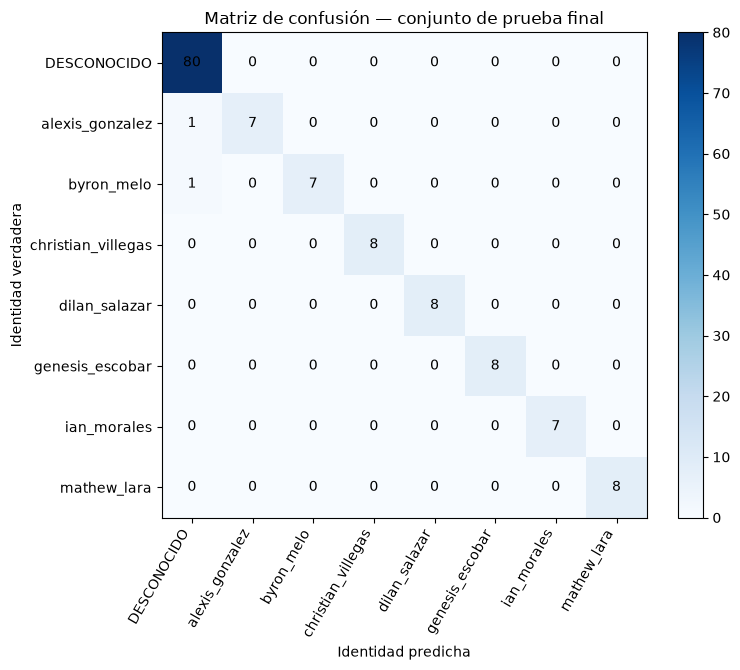

                    precision    recall  f1-score   support

       DESCONOCIDO       0.98      1.00      0.99        80
   alexis_gonzalez       1.00      0.88      0.93         8
        byron_melo       1.00      0.88      0.93         8
christian_villegas       1.00      1.00      1.00         8
     dilan_salazar       1.00      1.00      1.00         8
   genesis_escobar       1.00      1.00      1.00         8
       ian_morales       1.00      1.00      1.00         7
       mathew_lara       1.00      1.00      1.00         8

          accuracy                           0.99       135
         macro avg       1.00      0.97      0.98       135
      weighted avg       0.99      0.99      0.98       135

NOTA: el accuracy global del classification_report incluye desconocidos y puede superar la exactitud de socios.


In [11]:
# Matriz de confusión: filas = identidad real, columnas = predicción.
# Incorpora desconocidos externos válidos si existen. Evitamos mezclar escenarios de galería distinta.
y_real = prueba_socios["persona"].tolist()
y_pred = np.where(acepta_socios, prueba_socios["mejor"], "DESCONOCIDO").tolist()
y_real += ["DESCONOCIDO"] * len(d_test_ext)
y_pred += ["DESCONOCIDO" if d > UMBRAL_FINAL else "SOCIO_ACEPTADO" for d in d_test_ext]
# Para visualizar la aceptación errónea de un externo con identidad concreta:
if len(d_test_ext):
    G, etq = galeria
    Xext = np.stack([vectores_ext[r] for r in ext_test["ruta"]]).astype(np.float32)
    Dext = np.clip(1.0 - Xext @ G.T, 0, 2)
    idx_ext = Dext.argmin(axis=1)
    y_pred[-len(d_test_ext):] = [etq[i] if d <= UMBRAL_FINAL else "DESCONOCIDO" for i, d in zip(idx_ext, d_test_ext)]

etiquetas = sorted(set(y_real) | set(y_pred))
cm = confusion_matrix(y_real, y_pred, labels=etiquetas)
fig, ax = plt.subplots(figsize=(max(7, len(etiquetas)), max(6, len(etiquetas) * 0.85)))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(len(etiquetas)), etiquetas, rotation=60, ha="right")
ax.set_yticks(range(len(etiquetas)), etiquetas)
ax.set_xlabel("Identidad predicha"); ax.set_ylabel("Identidad verdadera")
ax.set_title("Matriz de confusión — conjunto de prueba final")
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(j, i, str(cm[i, j]), ha="center", va="center")
fig.colorbar(im, ax=ax, fraction=0.04); plt.tight_layout(); plt.show()
print(classification_report(y_real, y_pred, labels=etiquetas, zero_division=0))
print("NOTA: el accuracy global del classification_report incluye desconocidos y puede superar la exactitud de socios.")

### Interpretación académica de precisión, recall, F1 y soporte

En una matriz de confusión, **las filas representan la identidad real** y **las columnas la identidad predicha**. `DESCONOCIDO` es una categoría de salida del sistema.

- **Precision (precisión por clase):** TP/(TP+FP). De todas las veces que el sistema predijo una identidad, ¿qué proporción era realmente correcta? No equivale a reconocer todas las fotografías de esa identidad.
- **Recall (sensibilidad por clase):** TP/(TP+FN). De todas las consultas de esa persona, ¿qué proporción se identificó correctamente? Un socio rechazado como desconocido reduce su recall.
- **F1-score:** media armónica de precisión y recall, `2×precision×recall/(precision+recall)` cuando el denominador es distinto de cero.
- **Support (soporte):** cantidad de ejemplos reales de la clase evaluada.
- **Accuracy global del reporte:** aciertos de **todas las clases incluidas**, incluidos desconocidos; **no** debe confundirse con la exactitud de socios que se reporta por separado.

**Ejemplo de esta ejecución:** Alexis y Byron obtuvieron cada uno **7/8 reconocimientos correctos** (recall = 0,875), mientras que las otras cinco personas obtuvieron todos sus ejemplos de prueba correctamente identificados. No se observaron confusiones de identidad entre socios; hubo dos rechazos de consultas legítimas.

**Intervalo de confianza de Wilson (IC95):** ofrece un rango aproximado compatible con la proporción observada. El intervalo de exactitud de socios fue aproximadamente **87,7 %–99,0 %** para 53/55. Para FAR externa, aunque se observaron 0/80 falsas aceptaciones, el límite superior fue aproximadamente **4,6 %**. Esto **no demuestra** que la FAR poblacional sea menor de 1 %.


In [12]:
# Diagnóstico DESCRIPTIVO de socios reservados: no recalibrar el umbral con estos resultados.
diagnostico = prueba_socios.copy()
diagnostico["aceptada"] = diagnostico["distancia"].to_numpy() <= UMBRAL_FINAL
diagnostico["prediccion"] = np.where(diagnostico["aceptada"], diagnostico["mejor"], "DESCONOCIDO")
diagnostico["correcta"] = diagnostico["prediccion"] == diagnostico["persona"]
diagnostico["exceso_sobre_umbral"] = (diagnostico["distancia"] - UMBRAL_FINAL).round(4)
display(diagnostico.groupby("persona")["correcta"].agg(aciertos="sum", intentos="count", exactitud="mean"))
print("Fotografías de prueba rechazadas o confundidas (ordenadas por distancia):")
display(diagnostico.loc[~diagnostico["correcta"],
      ["persona", "foto", "prediccion", "distancia", "exceso_sobre_umbral"]].sort_values("distancia"))
diagnostico.to_csv(CARPETA_SALIDA / "diagnostico_prueba.csv", index=False)


,aciertos,intentos,exactitud
persona,,,
alexis_gonzalez,7,8,0.875
byron_melo,7,8,0.875
christian_villegas,8,8,1.000
dilan_salazar,8,8,1.000
genesis_escobar,8,8,1.000
ian_morales,7,7,1.000
mathew_lara,8,8,1.000


Fotografías de prueba rechazadas o confundidas (ordenadas por distancia):


,persona,foto,prediccion,distancia,exceso_sobre_umbral
5,alexis_gonzalez,Foto_5.jpg,DESCONOCIDO,0.265967,0.0060
9,byron_melo,foto_07.jpg,DESCONOCIDO,0.331779,0.0718


### Análisis de errores, condiciones de captura y latencia

La tabla de diagnóstico informa la identidad real, la predicción y la distancia para cada error del subconjunto de prueba. **Exceso sobre umbral = distancia mínima − umbral**: un número positivo indica que la consulta fue rechazada por superar el límite. Esta información ayuda a describir fallos, **no autoriza recalibrar** tras observar el conjunto de prueba.

Para analizar robustez, se admite de forma opcional un CSV `condiciones_fotos.csv` con columnas `persona,foto,condicion`. Estas etiquetas permiten medir la exactitud según iluminación, lentes o pose; **no sirven para entrenar ni mejorar automáticamente el modelo**. Sin el CSV, se utiliza solo una agrupación aproximada basada en el brillo del rostro.

MTCNN detecta rostros: no comprueba de forma fiable gorras, lentes o autenticidad de una persona frente a una cámara. Una política para rechazar gorras o fotografías impresas requeriría detectores o comprobaciones adicionales en el servicio, junto con nuevas pruebas de validación.

La latencia local se estima repitiendo extracción y control de calidad sobre hasta ocho imágenes reservadas. **No incluye** comunicación Flutter–API, consulta a PostgreSQL ni tiempo de red, por lo que no equivale al tiempo total de respuesta de la aplicación.


In [13]:
# Robustez por iluminación, sin inventar etiquetas que el equipo no recopiló.
cond_ruta = RAIZ / "condiciones_fotos.csv"
prueba_calidad = prueba_socios.merge(prueba[["persona", "foto", "brillo"]], on=["persona", "foto"], how="left")
prueba_calidad["condicion"] = np.select(
    [prueba_calidad["brillo"] < 70, prueba_calidad["brillo"] > 200],
    ["poca_luz", "mucha_luz"], default="luz_normal")
if cond_ruta.exists():
    condiciones = pd.read_csv(cond_ruta)[["persona", "foto", "condicion"]].dropna(subset=["condicion"])
    mapa = {(r.persona, r.foto): str(r.condicion) for r in condiciones.itertuples(index=False)}
    prueba_calidad["condicion"] = [mapa.get((p, f), c) for p, f, c in zip(prueba_calidad.persona, prueba_calidad.foto, prueba_calidad.condicion)]
prueba_calidad["correcta"] = (prueba_calidad["distancia"] <= UMBRAL_FINAL) & (prueba_calidad["mejor"] == prueba_calidad["persona"])
robustez = prueba_calidad.groupby("condicion")["correcta"].agg(["sum", "count", "mean"])
robustez["exactitud_%"] = (100 * robustez["mean"]).round(1)
display(robustez[["sum", "count", "exactitud_%"]])

# Cronometramos varias fotografías reservadas; DeepFace ya se cargó durante la extracción.
mediciones = []
for ruta in prueba["ruta"].head(min(8, len(prueba))):
    comienzo = time.perf_counter()
    resultado = extraer_embedding(ruta)
    mediciones.append(time.perf_counter() - comienzo)
    assert resultado["estado"] == "OK", "Una foto válida dejó de ser procesable. Revisa consistencia de la extracción."
tiempo_medio = float(np.mean(mediciones))
metricas_finales["tiempo_medio_inferencia_seg"] = tiempo_medio
metricas_finales["cumple_exactitud_observada_95"] = bool(metricas_finales["exactitud_socios"] >= 0.95)
metricas_finales["cumple_far_ocultos_observada_1"] = bool(metricas_finales["FAR_ocultos"] <= FAR_MAX)
metricas_finales["cumple_far_externos_observada_1"] = (bool(metricas_finales["FAR_externos"] <= FAR_MAX) if len(d_test_ext) else None)
metricas_finales["cumple_error_identidad_observada_1"] = bool(metricas_finales["tasa_error_identidad"] <= 0.01)
metricas_finales["cumple_latencia_observada_3s"] = bool(tiempo_medio <= 3.0)
print(f"Latencia media: {tiempo_medio:.2f} s (sobre {len(mediciones)} fotos; mínimo {min(mediciones):.2f}, máximo {max(mediciones):.2f})")
print("Metas observadas (sin garantía estadística):", {k: v for k, v in metricas_finales.items() if k.startswith("cumple_")})

,sum,count,exactitud_%
condicion,,,
luz_normal,48,50,96.0
poca_luz,5,5,100.0


Latencia media: 0.42 s (sobre 8 fotos; mínimo 0.40, máximo 0.50)
Metas observadas (sin garantía estadística): {'cumple_exactitud_observada_95': True, 'cumple_far_ocultos_observada_1': False, 'cumple_far_externos_observada_1': True, 'cumple_error_identidad_observada_1': True, 'cumple_latencia_observada_3s': True}


In [14]:
# Pruebas exploratorias ADICIONALES con imágenes NUEVAS, sin recalibrar el umbral.
# Formatos admitidos:
# pruebas_robustez/<condicion>/<persona_conocida>/foto.jpg -> reconocimiento de un SOCIO por condición.
# pruebas_robustez/<condicion>/foto.jpg -> DESCONOCIDO externo (sin identidad); no prueba detección de accesorios.
CARPETA_ROBUSTEZ = RAIZ / "pruebas_robustez"
filas_robustez = []
if CARPETA_ROBUSTEZ.is_dir():
    for ruta in sorted(CARPETA_ROBUSTEZ.rglob("*")):
        if not ruta.is_file() or ruta.suffix.lower() not in EXT:
            continue
        partes = ruta.relative_to(CARPETA_ROBUSTEZ).parts
        if len(partes) == 3:
            condicion, persona, _ = partes
            tipo = "socio" if persona in set(galeria[1]) else "externo"
        elif len(partes) == 2:
            condicion, _ = partes
            persona, tipo = "DESCONOCIDO_EXTERNO", "externo"
        else:
            print("Ignorada: estructura de ruta no reconocida", ruta)
            continue
        resultado = extraer_embedding(ruta)
        if resultado["estado"] != "OK":
            decision, predicho = "REJECTED", None
        else:
            G, nombres = galeria
            d = np.clip(1.0 - G @ resultado["embedding"], 0, 2)
            j = int(np.argmin(d))
            decision = "ACCEPTED" if float(d[j]) <= UMBRAL_FINAL else "REJECTED"
            predicho = str(nombres[j]) if decision == "ACCEPTED" else None
        correcto = (decision == "REJECTED") if tipo == "externo" else (predicho == persona and decision == "ACCEPTED")
        filas_robustez.append({"condicion": condicion, "tipo": tipo, "persona_real": persona,
                                "estado_extraccion": resultado["estado"], "decision": decision,
                                "identidad_predicha": predicho, "correcto": bool(correcto)})
if filas_robustez:
    tabla_extra = pd.DataFrame(filas_robustez)
    display(tabla_extra.groupby(["tipo", "condicion"])["correcto"].agg(["sum", "count", "mean"]))
    tabla_extra.to_csv(CARPETA_SALIDA / "pruebas_robustez.csv", index=False)
    print("ACLARACIÓN: rechazar desconocidos con gorra NO demuestra que el sistema detecte gorras.")
    print("El reconocimiento de socios CON gorra solo mide identificación; no implementa prohibición de gorras.")
else:
    archivo_previo = CARPETA_SALIDA / "pruebas_robustez.csv"
    if archivo_previo.exists(): archivo_previo.unlink()  # evita confundir resultados antiguos con la ejecución actual
    print("No hay pruebas adicionales de robustez en pruebas_robustez/. Es opcional.")

sum  count  mean
tipo    condicion                  
externo gorra       12     12   1.0
        lentes       4      4   1.0

ACLARACIÓN: rechazar desconocidos con gorra NO demuestra que el sistema detecte gorras.
El reconocimiento de socios CON gorra solo mide identificación; no implementa prohibición de gorras.


## Fase 6. Preparación para el despliegue

Se exporta la **misma galería evaluada**: únicamente los vectores de `matricular`. Esta decisión conserva la correspondencia entre la configuración validada, los resultados reportados y la versión inicial que se cargará en PostgreSQL. Agregar las fotografías reservadas a la galería en esta etapa cambiaría el experimento y exigiría una nueva evaluación.

**Artefactos principales:**

- `galeria_embeddings.json`: identidad, archivo de origen y vector normalizado de 512 dimensiones de cada fotografía de matriculación.
- `config_reconocimiento.json`: versiones, detector, normalización, umbral de distancia coseno, filtros de calidad y política de aceptación.
- `metricas_evaluacion.json`: resultados medidos, incluyendo exactitud de socios, FAR externa y FAR de identidades ocultas.
- `calidad_fotos.csv`, `particion.csv`, `diagnostico_prueba.csv` y `mosaicos/`: evidencia del procesamiento y la evaluación.

**Arquitectura posterior:** Flutter permitirá matricular nuevos usuarios y enviar capturas; FastAPI reutilizará la extracción FaceNet512+MTCNN y aplicará la regla de decisión; PostgreSQL con `pgvector` almacenará usuarios, embeddings y asistencias. **Agregar usuarios no requiere reentrenar el modelo**, pero sí revisar el desempeño con el crecimiento de la galería. Se planificará también una política de prevención de accesos repetidos y comprobaciones contra suplantación.

**Seguridad y límites:** el umbral no constituye una garantía de identidad ni una protección contra fotografías o videos mostrados ante la cámara; un detector de vitalidad (*liveness*) y controles de acceso serían necesarios para un sistema operativo.


In [15]:
# Esquema de exportación estable (NO reentrena ni copia pesos de FaceNet512).
registros_galeria = [
    {"persona": r.persona, "foto": r.foto, "embedding": [float(x) for x in vectores[r.ruta]]}
    for r in matricular.itertuples(index=False)
]
config_exportada = {
    "proyecto": "control_asistencia_gimnasio", "version": "1.1.0",
    "fecha_exportacion_utc": datetime.now(timezone.utc).isoformat(),
    "modelo": MODELO, "detector": DETECTOR, "align": ALINEAR,
    "normalization_deepface": NORMALIZACION_DEEPFACE,
    "modelo_preentrenado": True, "requiere_entrenamiento": False,
    "embedding_dim": 512, "embedding_normalizado_l2": True,
    "distancia": "cosine", "estrategia": "todos_min",
    "regla_aceptacion": "distancia_minima <= umbral",
    "umbral": UMBRAL_FINAL,
    "preprocesamiento": {"max_lado_imagen": MAX_LADO_IMAGEN, "min_lado_rostro": MIN_LADO_ROSTRO,
                           "confianza_minima": MIN_CONFIANZA, "brillo_admitido": list(BRILLO_RECHAZO),
                           "nitidez_minima": NITIDEZ_RECHAZO},
    "galeria": {"personas": int(matricular["persona"].nunique()), "embeddings": len(registros_galeria),
                 "origen": "particion_matricular_sin_validacion_ni_prueba"},
    "negocio": {"ventana_duplicado_minutos": 5, "estados_asistencia": ["ACCEPTED", "REJECTED", "DUPLICATE"]},
    "deepface_version": getattr(deepface, "__version__", "no informada"),
}
for nombre, contenido in [
    ("galeria_embeddings.json", {"formato": "galeria_facenet512_v1", "registros": registros_galeria}),
    ("config_reconocimiento.json", config_exportada),
    ("metricas_evaluacion.json", metricas_finales),
]:
    with (CARPETA_SALIDA / nombre).open("w", encoding="utf-8") as f:
        json.dump(contenido, f, indent=2 if "galeria" not in nombre else None, ensure_ascii=False, allow_nan=False)

# Verificación: leer los artefactos DESDE DISCO y comparar uno de los rostros de prueba.
with (CARPETA_SALIDA / "config_reconocimiento.json").open(encoding="utf-8") as f:
    cfg_recargada = json.load(f)
with (CARPETA_SALIDA / "galeria_embeddings.json").open(encoding="utf-8") as f:
    exportacion = json.load(f)["registros"]
G_recargada = np.stack([vector_unitario(r["embedding"]) for r in exportacion])
nombres_recargados = np.array([r["persona"] for r in exportacion])
assert len(G_recargada) == cfg_recargada["galeria"]["embeddings"]
assert G_recargada.shape[1] == 512
r = prueba.iloc[0]
resultado_recargado = puntuar(prueba.iloc[[0]], (G_recargada, nombres_recargados)).iloc[0]
resultado_original = puntuar(prueba.iloc[[0]], galeria).iloc[0]
assert abs(float(resultado_recargado["distancia"]) - float(resultado_original["distancia"])) < 1e-5
print("Exportación verificada:", CARPETA_SALIDA)
print("Galería:", len(G_recargada), "vectores de", G_recargada.shape[1], "dimensiones")
print("Umbral exportado:", cfg_recargada["umbral"], "| prueba recarga:", resultado_recargado["mejor"])
print("Nuevos socios se matricularán después en PostgreSQL sin reentrenar FaceNet512.")
print("Archivos:", [p.name for p in sorted(CARPETA_SALIDA.iterdir()) if p.is_file()])

Exportación verificada: C:\Users\Arman\Desktop\machine_learning_II\Proyecto Final\modelo_exportado
Galería: 109 vectores de 512 dimensiones
Umbral exportado: 0.26 | prueba recarga: alexis_gonzalez
Nuevos socios se matricularán después en PostgreSQL sin reentrenar FaceNet512.
Archivos: ['calidad_fotos.csv', 'config_reconocimiento.json', 'diagnostico_prueba.csv', 'galeria_embeddings.json', 'metricas_evaluacion.json', 'particion.csv', 'pruebas_robustez.csv']


## Conclusiones y decisiones documentadas por fase CRISP-DM

1. **Comprensión del negocio.** Se estableció como objetivo un prototipo de asistencias que reconozca socios y rechace desconocidos, con registro posterior de intentos y prevención de duplicados en la API.
2. **Comprensión de los datos.** Se recibieron 196 imágenes de 7 participantes; la muestra es pequeña y algunas sesiones de captura presentan fondos y condiciones similares.
3. **Preparación.** MTCNN y FaceNet512 generaron embeddings utilizables para 191 imágenes. Las cinco imágenes marcadas como `VARIOS_ROSTROS` requieren revisión, pues una detección adicional no significa necesariamente una segunda persona real.
4. **Modelado.** Se implementó identificación por distancia coseno mínima con FaceNet512 preentrenado, **sin transfer learning ni reentrenamiento**.
5. **Evaluación.** Con umbral calibrado **0,260**, se reconocieron **53/55 consultas de socios (96,4 %)**; hubo **2 rechazos (FRR 3,6 %)** y **0 confusiones entre socios**. En desconocidos externos hubo **0/80 falsas aceptaciones observadas**; en el ensayo de identidades ocultas hubo **1/55 (FAR 1,8 %)**. Por tanto, **no se cumplió** el objetivo experimental de FAR ocultas ≤1 %. La exactitud de socios sí superó la meta observada de 95 %, pero la muestra no demuestra desempeño real garantizado.
6. **Preparación del despliegue.** Se exportaron 109 embeddings de matriculación y la configuración exacta para iniciar la API y la base de datos. La matriculación de nuevos socios no requiere cambiar los pesos de FaceNet512.

**Decisión final.** El módulo facial se considera un **prototipo funcional apto para comenzar la integración local**. No se presenta como un sistema biométrico listo para producción: se necesitan capturas independientes con cámara real, pruebas de falsos accesos, controles contra suplantación, cuidado de la privacidad y seguimiento de FAR/FRR al crecer la base de usuarios.